# 03 · Feed-forward Neural Network

A multilayer perceptron (MLP) in PyTorch, trained on both tasks.

* **Model:** `NeuralNetClassifier` in `src/comp472_project/models/neural_net.py`: `Linear → ReLU → Dropout` blocks, then a `Linear` output layer; cross-entropy loss, mini-batches of 128.
* **Experiments:** `scripts/nn_experiments.py` changes **one hyperparameter at a time** from a shared base configuration (2 hidden layers of 256 and 64 units, Adam, learning rate 0.001, standardised inputs, 40 epochs), so each difference in a plot has one cause. Results are saved to `results/neural_net.csv` (one row per run) and `results/neural_net_history.csv` (one row per epoch); this notebook only reads them, so it runs in about two minutes.
* **Validation:** the same fixed 80/20 split as every other model (`data/splits/`). Preprocessing is fitted on the 80% only.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from comp472_project.config import FIGURES_DIR, RESULTS_DIR, SEED, SENTIMENT_LABELS, seed_everything
from comp472_project.data import load_split
from comp472_project.evaluation import accuracy, confusion_matrix, most_confused_pairs, per_class_accuracy
from comp472_project.models import KNNClassifier, NeuralNetClassifier
from comp472_project.models.neural_net import TUNED_CONFIGS
from comp472_project.preprocessing import SqrtTransform, Standardizer

runs = pd.read_csv(RESULTS_DIR / "neural_net.csv")
history = pd.read_csv(RESULTS_DIR / "neural_net_history.csv")
print(f"{len(runs)} training runs, {len(history)} epoch rows")

36 training runs, 1440 epoch rows


## 1. All sweeps at a glance

`final_val_acc` is validation accuracy after the last epoch; `best_val_acc` is the best epoch. A large gap between them, or between `final_train_acc` and `final_val_acc`, means overfitting.

In [2]:
cols = ["task", "sweep", "setting", "final_train_acc", "final_val_acc", "best_val_acc", "best_epoch", "fit_time_s"]
(runs[cols].style.format({c: "{:.3f}" for c in ["final_train_acc", "final_val_acc", "best_val_acc"]})
     .background_gradient(subset=["final_val_acc"], cmap="Greens").hide(axis="index"))

task,sweep,setting,final_train_acc,final_val_acc,best_val_acc,best_epoch,fit_time_s
image,preprocessing,none,0.727,0.308,0.308,36,12.370000
image,preprocessing,standard,1.000,0.336,0.340,22,8.960000
image,preprocessing,l2,0.727,0.309,0.309,40,11.070000
image,lr,0.1,0.020,0.020,0.020,1,14.160000
image,lr,0.01,0.610,0.202,0.224,14,11.010000
image,lr,0.001,1.000,0.336,0.340,22,9.910000
image,lr,0.0001,0.755,0.320,0.320,40,9.490000
image,hidden,64,0.883,0.255,0.301,7,5.670000
image,hidden,256,1.000,0.343,0.347,7,8.690000
image,hidden,512,1.000,0.369,0.370,39,13.120000


## 2. Learning rate

Adam with learning rates 0.1, 0.01, 0.001 and 0.0001. **Solid lines are validation, dashed are training.**

* **0.1** is too large: the loss diverges and the network predicts a single class (2% = 1/50 on images, 33% = 1/3 on sentiment).
* **0.01** learns but is noisy and ends well below 0.001.
* **0.001** learns fastest, but training accuracy reaches 100% within a few epochs while validation accuracy stalls: classic overfitting.
* **0.0001** learns slowly and steadily; on sentiment it reaches roughly the same peak as 0.001 a few epochs later.

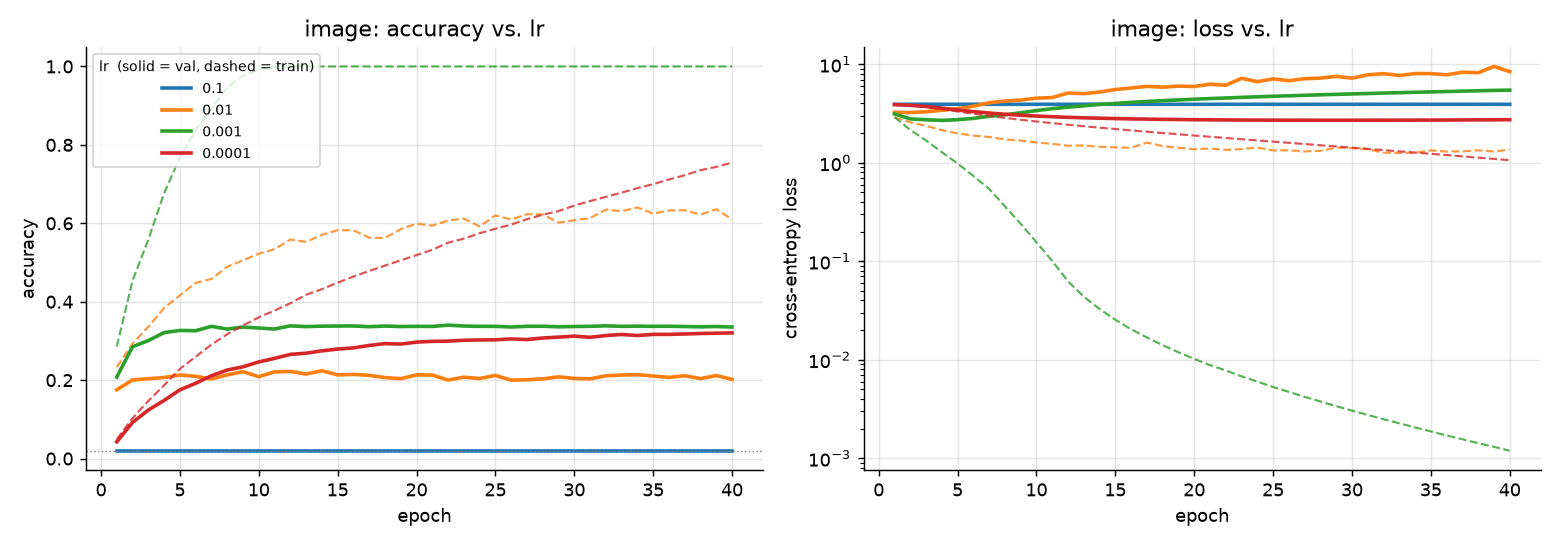

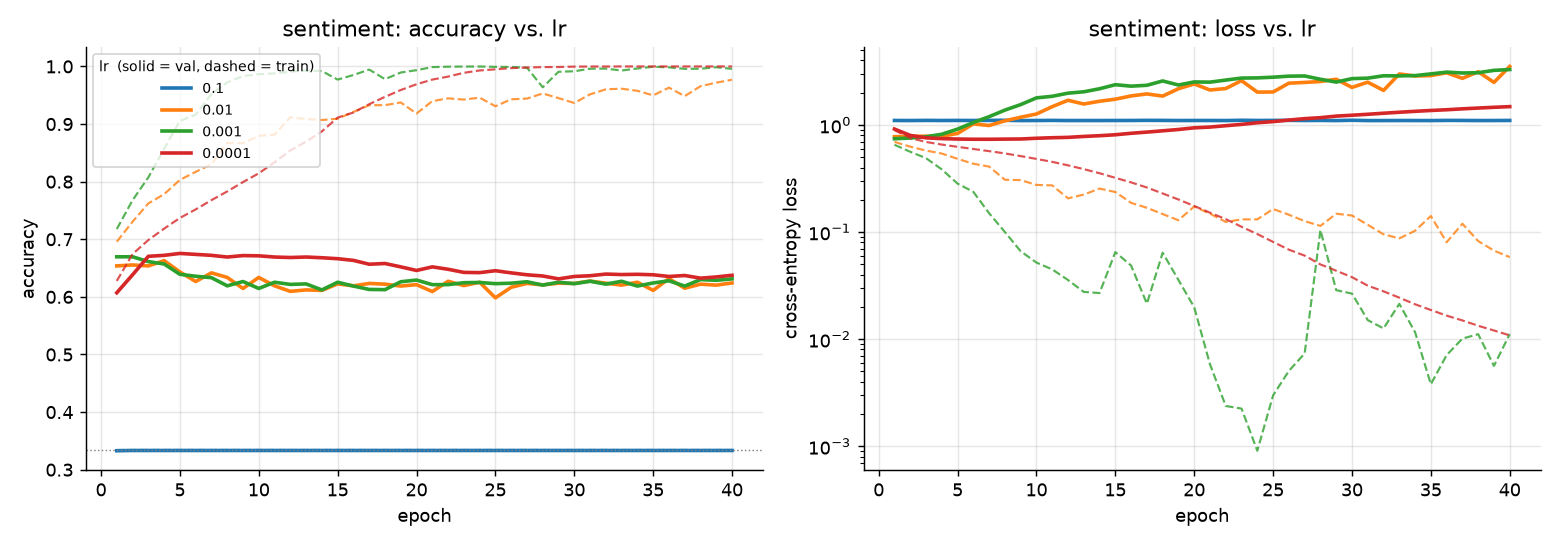

In [3]:
for task in ["image", "sentiment"]:
    display(Image(FIGURES_DIR / f"nn_{task}_lr.png"))

## 3. Hidden-layer sizes

From one layer of 64 units up to two layers of 1024 and 512.

* **Images:** wider is better (33.6% for 256-64 up to 38.3% for 1024-512): with 50 classes and 500 inputs, small layers are a bottleneck. All sizes still reach 100% training accuracy.
* **Sentiment:** size barely matters (best epoch 66-68% for every size). The BERT embeddings are already high-level features, so extra capacity just overfits sooner.

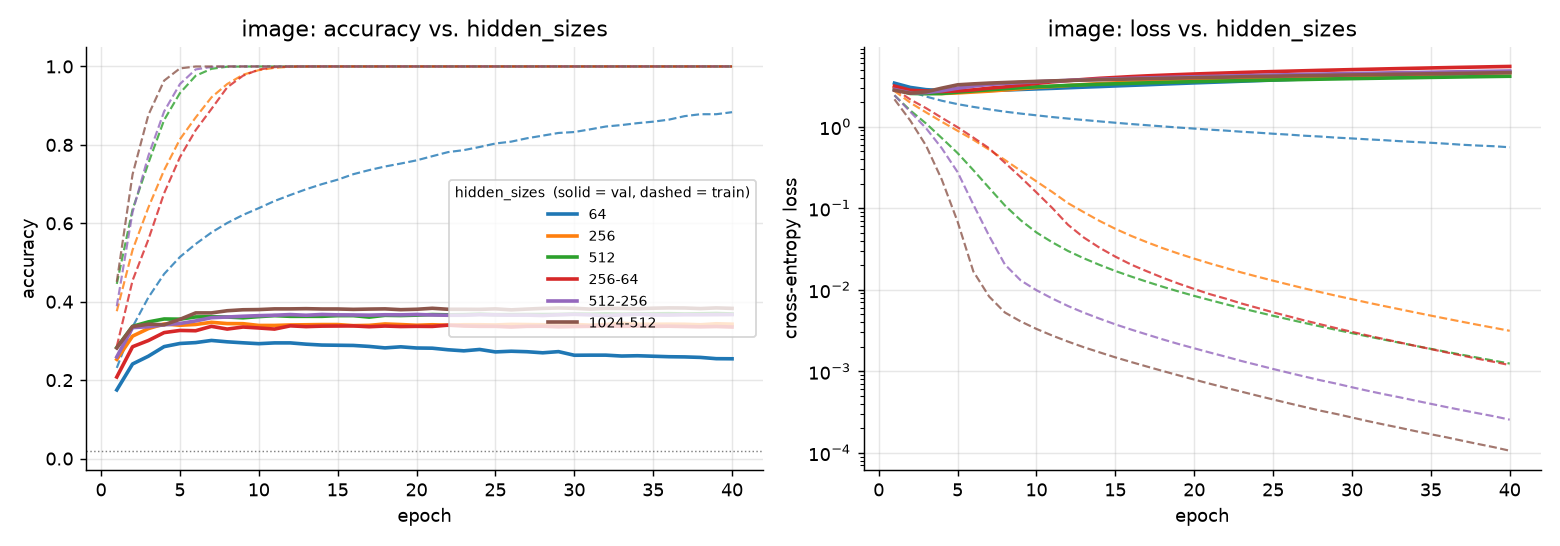

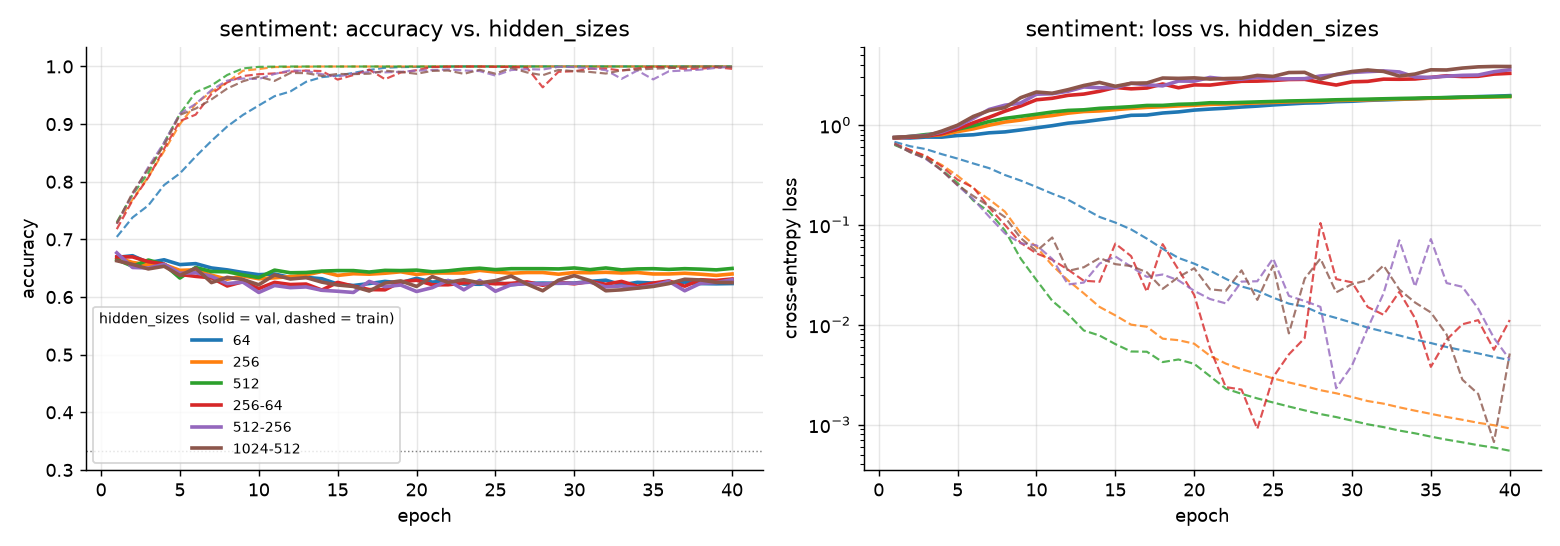

In [4]:
for task in ["image", "sentiment"]:
    display(Image(FIGURES_DIR / f"nn_{task}_hidden.png"))

## 4. Preprocessing and dropout

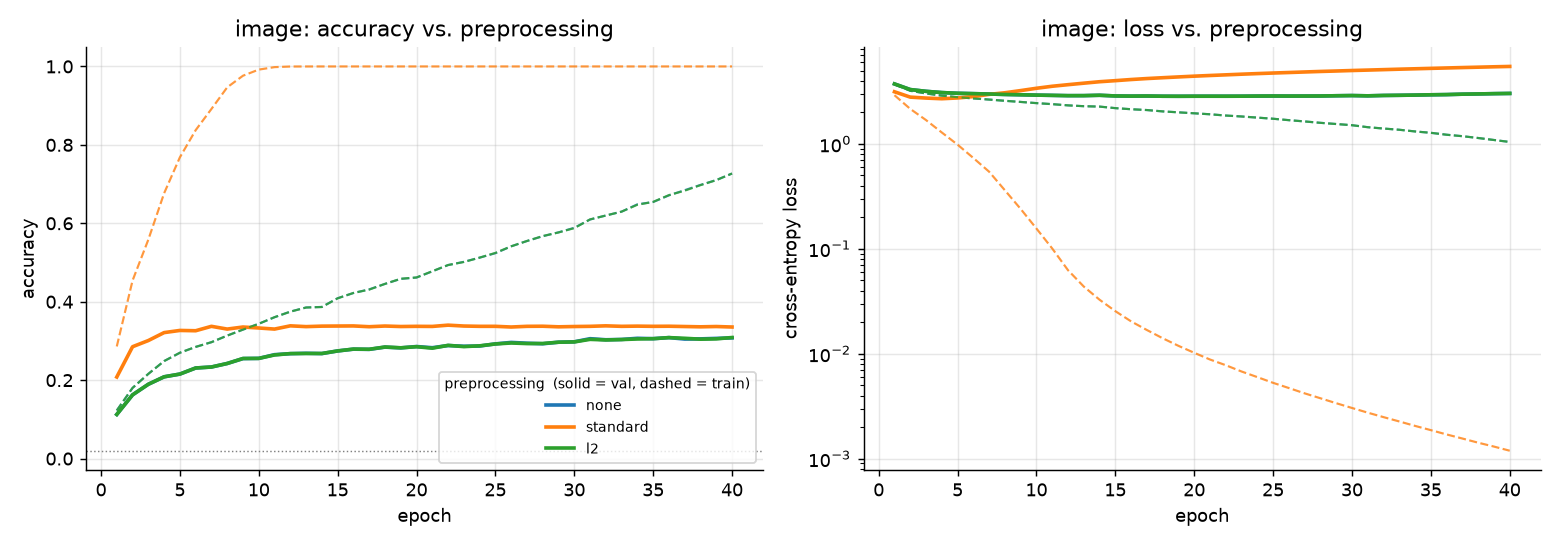

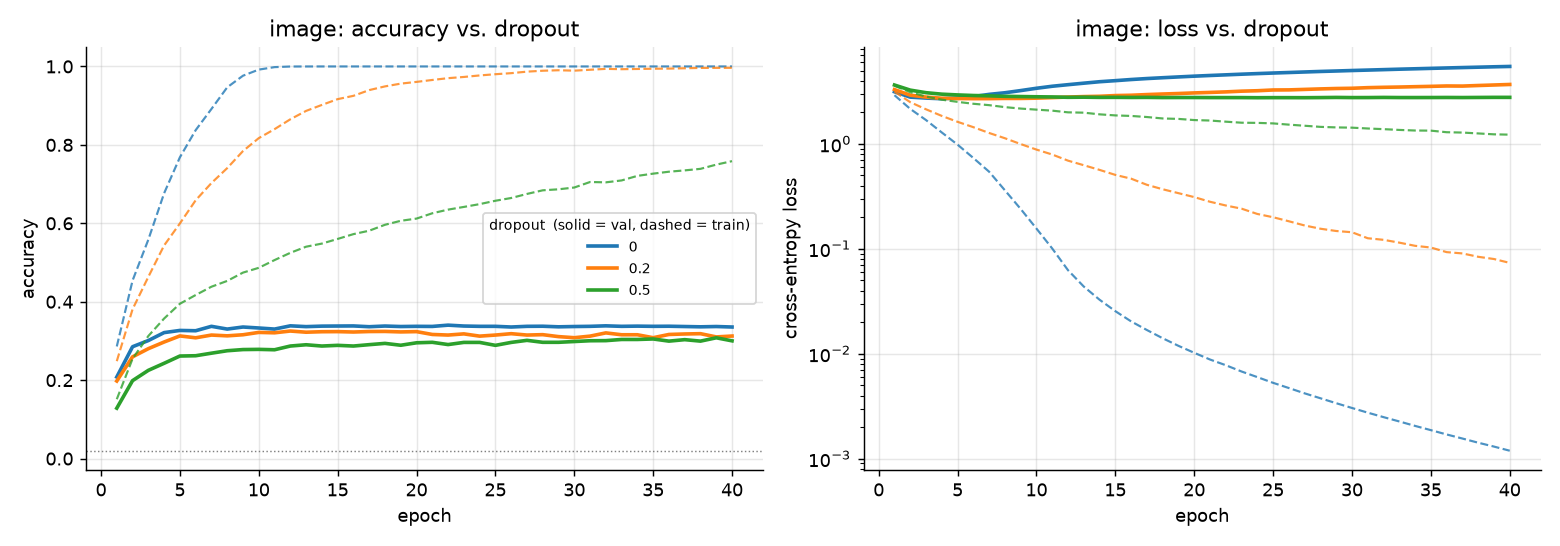

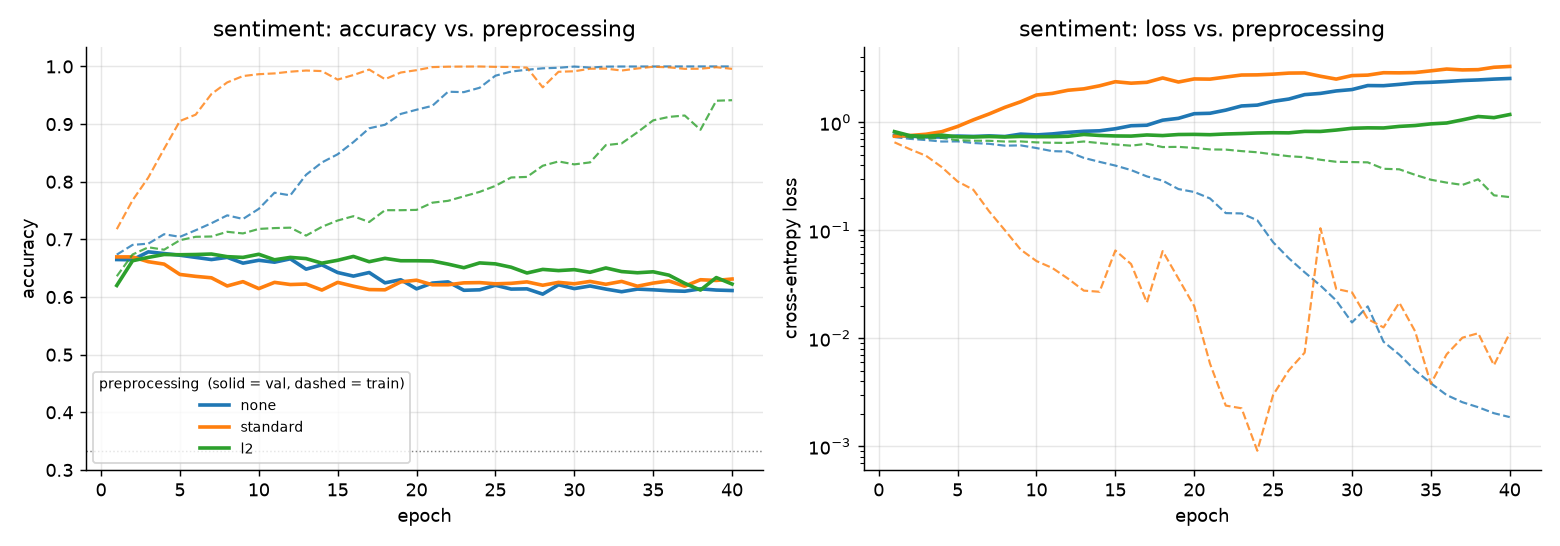

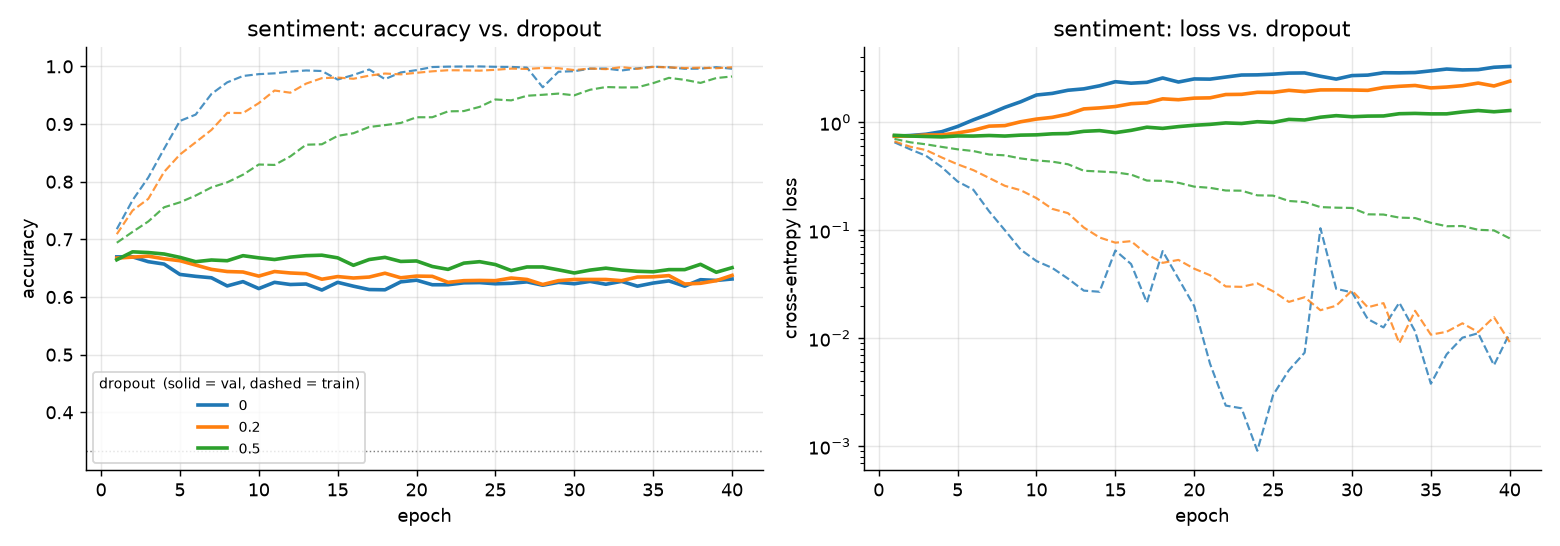

In [5]:
for task in ["image", "sentiment"]:
    for sweep in ["preprocessing", "dropout"]:
        display(Image(FIGURES_DIR / f"nn_{task}_{sweep}.png"))

* **Preprocessing:** standardising (zero mean, unit variance per feature, fitted on train) helps on images (30.8% → 33.6%), whose raw values are tiny. On sentiment, all three options peak at about 67-68%; they differ mainly in how fast they overfit afterwards.
* **Dropout alone** delays overfitting on sentiment (final val 63.1% → 65.1% with 0.5) but hurts images at this size. It works on images only when combined with a wider network (section 5).

## 5. Final configurations: base vs. tuned

The sweeps show the main problem is **overfitting**, so each final configuration combines several fixes (`TUNED_CONFIGS` in `models/neural_net.py`):

In [6]:
pd.DataFrame(TUNED_CONFIGS).T

,preprocessing,hidden_sizes,dropout,lr,optimizer,weight_decay,epochs,scheduler
image,sqrt+standard,"(1024, 512)",0.5,0.001,adamw,0.1,60,cosine
sentiment,standard,"(512,)",0.5,0.0001,adamw,0.1,20,cosine


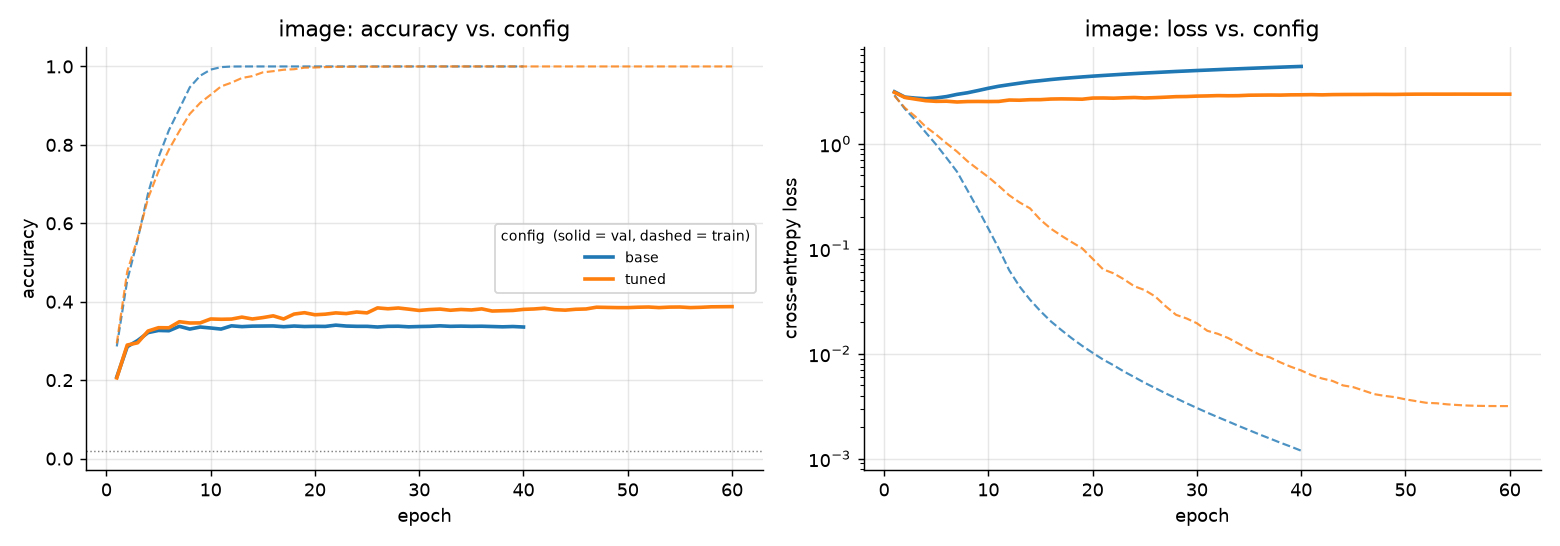

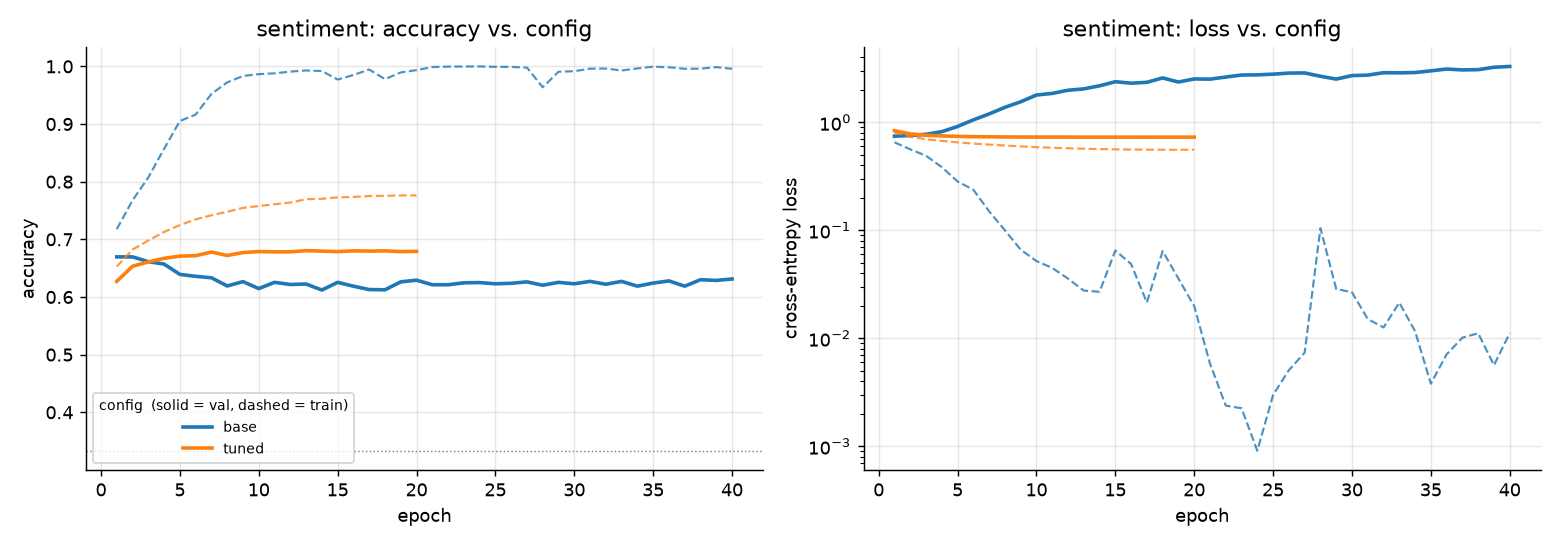

,task,setting,final_train_acc,final_val_acc,best_val_acc
16,image,base,1.000000,0.335500,0.340250
17,image,tuned,1.000000,0.387500,0.387500
34,sentiment,base,0.995833,0.631250,0.669583
35,sentiment,tuned,0.776146,0.679167,0.680417


In [7]:
for task in ["image", "sentiment"]:
    display(Image(FIGURES_DIR / f"nn_{task}_tuned.png"))
runs.query("sweep == 'tuned'")[["task", "setting", "final_train_acc", "final_val_acc", "best_val_acc"]]

* **Sentiment: 63.1% → 67.9%.** A 10× smaller learning rate, dropout 0.5 and AdamW weight decay 0.1 with cosine learning-rate decay. Training and validation curves now stay close, and the final epoch is within 0.1 points of the best one, so the result does not depend on picking the right epoch.
* **Images: 33.6% → 38.7%.** Square-rooting the count features first (see section 7), a wider network (1024-512), dropout 0.5 and weight decay. Training accuracy is still 100%: the overfitting is reduced, not removed.

## 6. Error analysis: sentiment

Retrain the tuned sentiment network on the 80% split (≈7 s) and look at what it gets wrong on the 2,400 validation tweets.

In [8]:
def fit_tuned(task, data):
    cfg = dict(TUNED_CONFIGS[task])
    prep = cfg.pop("preprocessing")
    transforms = {"standard": [Standardizer()], "sqrt+standard": [SqrtTransform(), Standardizer()]}[prep]
    X_train, X_val = data.X_train, data.X_val
    for t in transforms:
        X_train = t.fit_transform(X_train, data.y_train)
        X_val = t.transform(X_val)
    seed_everything()
    model = NeuralNetClassifier(**cfg, seed=SEED).fit(X_train, data.y_train)
    return model.predict(X_val)

sent = load_split("sentiment")
sent_pred = fit_tuned("sentiment", sent)
print(f"validation accuracy: {accuracy(sent.y_val, sent_pred):.4f}")

cm = confusion_matrix(sent.y_val, sent_pred, 3)
names = [SENTIMENT_LABELS[i] for i in range(3)]
cm_df = pd.DataFrame(cm, index=[f"true {n}" for n in names], columns=[f"pred {n}" for n in names])
cm_df["recall"] = per_class_accuracy(cm).round(3)
cm_df

validation accuracy: 0.6792


,pred Negative,pred Neutral,pred Positive,recall
true Negative,609,133,58,0.761
true Neutral,164,466,170,0.582
true Positive,78,167,555,0.694


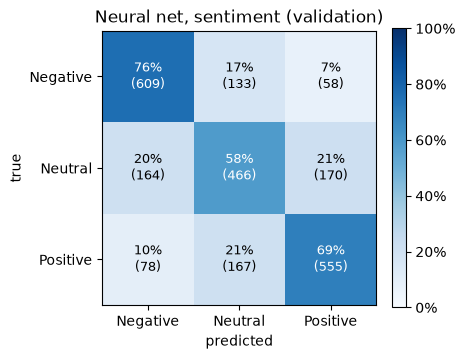

In [9]:
fig, ax = plt.subplots(figsize=(4.6, 4))
norm = cm / cm.sum(axis=1, keepdims=True)
im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{norm[i, j]:.0%}\n({cm[i, j]})", ha="center", va="center",
                color="white" if norm[i, j] > 0.5 else "black", fontsize=9)
ax.set(xticks=range(3), yticks=range(3), xticklabels=names, yticklabels=names,
       xlabel="predicted", ylabel="true", title="Neural net, sentiment (validation)")
fig.colorbar(im, ax=ax, fraction=0.046, format=lambda x, _: f"{x:.0%}")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "nn_sentiment_confusion.png", dpi=130)
plt.show()

**Findings (sentiment):**
* **Neutral is the hard class:** recall 58%, against 76% for negative and 69% for positive.
* **Neutral errors are split evenly** between negative (164) and positive (170). Neutral sits *between* the other two, and a mildly worded tweet can fall on either side.
* **Negative ↔ positive mix-ups are the rarest errors** (58 and 78 out of 800 each). The network has learned polarity well; its trouble is deciding whether there is any sentiment at all.
* This matches notebook 02, where k-NN had the same problem even more strongly: on the test set it labelled only 11% of tweets neutral, against 28% for the network.

## 7. Why the network loses to k-NN on images

The tuned network reaches 38.7% on images while 1-nearest-neighbour reaches 52-56%. Smaller k being better for k-NN (notebook 02) hints that the answer is often a single, very similar training image. Measure it directly: for each validation image, find its most similar training image (cosine similarity) and check whether it has the same label.

In [10]:
img = load_split("image")
sq = SqrtTransform()
unit = lambda X: X / np.linalg.norm(X, axis=1, keepdims=True)
Xtr, Xval = unit(sq.transform(img.X_train)), unit(sq.transform(img.X_val))
sim = Xval @ Xtr.T
nearest = sim.argmax(axis=1)
top_sim = sim.max(axis=1)
nn_correct = img.y_train[nearest] == img.y_val

img_pred = fit_tuned("image", img)  # ≈ 80 s
mlp_correct = img_pred == img.y_val
print(f"1-NN (sqrt, cosine): {nn_correct.mean():.3f}   tuned MLP: {mlp_correct.mean():.3f}")

bins = pd.qcut(top_sim, 5)
by_sim = pd.DataFrame({"similarity to nearest train image": bins, "1-NN correct": nn_correct,
                       "MLP correct": mlp_correct}).groupby("similarity to nearest train image", observed=True).mean()
by_sim

1-NN (sqrt, cosine): 0.563   tuned MLP: 0.388


,1-NN correct,MLP correct
similarity to nearest train image,,
"(0.264, 0.367]",0.17750,0.18875
"(0.367, 0.433]",0.44125,0.28000
"(0.433, 0.507]",0.61750,0.40875
"(0.507, 0.576]",0.68625,0.45875
"(0.576, 0.954]",0.89125,0.60125


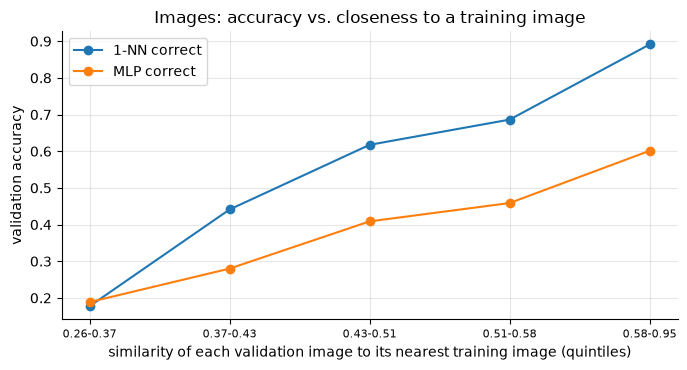

In [11]:
ax = by_sim.plot(marker="o", figsize=(7, 3.8))
ax.set(ylabel="validation accuracy", xlabel="similarity of each validation image to its nearest training image (quintiles)",
       title="Images: accuracy vs. closeness to a training image")
ax.set_xticks(range(len(by_sim)))
ax.set_xticklabels([f"{iv.left:.2f}-{iv.right:.2f}" for iv in by_sim.index], fontsize=8)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "nn_image_vs_1nn_similarity.png", dpi=130)
plt.show()

**Findings (images):**
* **k-NN's advantage comes almost entirely from near-duplicates.** In the top fifth of validation images (cosine similarity above 0.58 to some training image), 1-NN is right **89%** of the time and the network only **60%**.
* **With no close match, both models fail equally** (bottom fifth: 18% vs. 19%, the network slightly ahead).
* So many validation images have a near-copy in the training set. That is consistent with objects photographed several times from similar viewpoints, though we can't verify this from the features alone. Looking up the closest copy (k-NN) exploits it directly. The network instead learns a smooth function over the whole space, which reached 100% training accuracy without reproducing those exact lookups.
* **Takeaway:** the right model depends on the structure of the features. The network is best on the BERT sentiment embeddings and worst on these image features.

## 8. Summary

| | Images | Sentiment |
|---|---|---|
| NN, base configuration | 33.6% | 63.1% |
| NN, tuned | **38.7%** | **67.9%** |
| k-NN (notebook 02, best) | 51.9% | 59.0% |
| 1-NN with square-root features | 56.3% | n/a |

* The network is the best model we have for **sentiment**, and the worst for **images**, so the submission uses k-NN for images and the network for sentiment (`scripts/make_submission.py --image knn --sentiment neural_net`).
* That combination scored **0.621** on validation and **0.627** on the Kaggle public leaderboard, so the validation split is a good predictor of the leaderboard.
* The final submitted models are retrained on 100% of the training data with the same settings; the 80% split is only used to choose those settings.